# 06 - XGBoost forecasts and allocation validation
Prediction and decision quality are separate objectives. Compare 14 profit models on rolling CP04-06 factual RMSE and 21 feasible allocation rules on rolling DR incremental NCM. Model-driven allocations now use the constrained greedy allocator. Deployment explicitly uses the forecast champion through config/allocation_policy.json; the validation winner remains separately reported. CP07 was previously inspected, so its evaluation is retrospective.


In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from src.common import TABLES, FIGS, MODELS, load_processed
from src.modeling import ACTIONS, COMMERCIAL, XGB_FIXED, feature_lists, predict_actions
from src.performance import run_performance_validation
df = load_processed("historical_feature_outcome")
NUM, CAT = feature_lists()
X_COLS = NUM + CAT
outcomes = set(pd.read_csv(TABLES/'outcome_schema.csv').outcome)
assert not set(X_COLS) & (outcomes | {'offer_type','assignment_source','customer_id','campaign_id','send_ts','assignment_id'})
exp = df[df.assignment_source.eq('exploration')]
print(len(exp), 'randomized training rows;', len(X_COLS), 'predecision predictors')

7527 randomized training rows; 43 predecision predictors


## Rebuild the development searches and evaluate frozen choices
The two-part XGBoost family estimates purchase probability times conditional signed buyer margin. It shares data across randomized arms, and tests shrinkage toward arm-specific buyer means. Negative margins remain possible. Selection uses earlier campaigns only. Segmented offer effects, pooled models, action means and simple feasible baselines compete for allocation. A confidence interval excluding zero is not required to select the validation winner; uncertainty is reported separately.

In [2]:
# Keep a local traceback log for long native-library calls; no targets or secrets are logged.
import faulthandler
trace_dir = Path.cwd().parent / '.validation-cache'
trace_dir.mkdir(exist_ok=True)
with (trace_dir/'model_execution_trace.log').open('w') as trace:
    faulthandler.dump_traceback_later(60,repeat=True,file=trace)
    try:
        selection, model_metrics, policy_metrics, final = run_performance_validation(df, NUM, CAT, TABLES, MODELS)
    finally:
        faulthandler.cancel_dump_traceback_later()
forecast = selection['forecast_model']
selected_policy = selection['selected_policy']
print('Forecast model:', forecast, '| Allocation rule:', selected_policy)
display(model_metrics.query("scope == 'pooled'"))
display(policy_metrics[['policy','dr_incremental_ncm_per_customer','ci_low','ci_high','offered_share']])
display(pd.read_csv(TABLES/'policy_candidate_selection.csv'))

Forecast model: HURDLE_XGB_HALF | Allocation rule: HURDLE_XGB_HALF


,model,scope,n,rmse,mae,r2,obs_mean,pred_mean,split
0,ORIGINAL_TLEARNER,pooled,1060,63.369408,27.411143,0.005863,15.31483,16.573692,CP07
5,HURDLE_XGB_HALF,pooled,1060,62.738470,26.480589,0.025561,15.31483,15.975588,CP07


,policy,dr_incremental_ncm_per_customer,ci_low,ci_high,offered_share
0,ORIGINAL_TLEARNER,3.971406,-2.231148,9.673656,0.6
1,ACTION_MEAN,12.523334,3.149427,22.517684,0.6
2,HURDLE_XGB_HALF,8.888760,0.252821,18.029904,0.6
3,ALL_NO_OFFER,0.000000,0.000000,0.000000,0.0
4,PROPENSITY_PCT10,3.650978,-2.492067,9.759834,0.6
5,HISTORICAL_MIX,4.659854,-0.483924,9.758685,0.6
6,RANDOM_FREE_SHIP,12.741429,3.589919,22.663654,0.6


,policy,n,development_dr_incremental_ncm
0,RANDOM_FREE_SHIP,3237,3.817569
1,HISTORICAL_MIX,3237,3.339480
2,SEGMENT_MEMBERSHIP_HISTORY_RIDGE_100,3237,2.079737
3,SEGMENT_MEMBERSHIP_HISTORY_RIDGE_20,3237,2.079737
4,ACTION_MEAN,3237,1.456858
5,SEGMENT_MEMBERSHIP_HISTORY_RIDGE_300,3237,0.912636
6,POOLED_XGBOOST,3237,0.449977
7,SEGMENT_MEMBERSHIP_CART_RIDGE_100,3237,0.378578
8,SEGMENT_MEMBERSHIP_CART_RIDGE_300,3237,0.378578
9,SEGMENT_MEMBERSHIP_RIDGE_100,3237,0.164695


## Save forecast metadata and diagnostics
Legacy tlearner model filenames contain the selected predictive model. policy_selection.json separately records the deployed greedy rule, its user-requested basis, and the development-validation winner. Deployment is not a claim that the model-driven allocation has proven superior policy value.


In [3]:
selected_metrics = model_metrics[model_metrics.model.eq(forecast)]
meta = {'target':'ncm_14d','training_population':'assignment_source == exploration','actions':ACTIONS,
        'numeric_features':NUM,'categorical_features':CAT,'selected_method':forecast,
        'selected_policy':selected_policy,'allocation_model':selection['allocation_model'],'allocator':selection['allocator'],'validation_selected_policy':selection['validation_selected_policy'],'forecast_config':selection['prediction_selection']['config'],
        'xgb_fixed':XGB_FIXED,'xgb_selected':{'n_estimators':100,'max_depth':1,'learning_rate':.03},
        'xgb_selected_role':'reference T-learner / existing cost-model parameters, not the selected hurdle configuration',
        'selection':selection['rule'],'final_train_rows':{a:int(exp.offer_type.eq(a).sum()) for a in ACTIONS},
        'cp07_pooled':selected_metrics.query("scope == 'pooled'").iloc[0][['rmse','mae','r2']].to_dict()}
(MODELS/'tlearner_metadata.json').write_text(json.dumps(meta,indent=2),encoding='utf-8')
final_mu = predict_actions(final, exp[X_COLS])
te = pd.read_csv(TABLES/'xgboost_test_predictions.csv')
step04 = pd.read_csv(TABLES/'incremental_ncm_exploration.csv').query("segment == 'exploration' and outcome == 'ncm_14d'").set_index('offer_type')
effects = pd.DataFrame({'action':ACTIONS,
    'model_mean_incremental_ncm_CP07':[te[f'incremental_ncm_{a}'].mean() for a in ACTIONS],
    'final_model_mean_incremental_ncm_all_exploration':(final_mu-final_mu[:,[0]]).mean(axis=0),
    'step04_randomized_effect_CP01_07':[0.]+[step04.loc[a,'incremental_ncm'] for a in COMMERCIAL],
    'interpretation':'model averages are diagnostic, not independent evidence of treatment-effect accuracy'})
effects.to_csv(TABLES/'tlearner_action_effect_summary.csv',index=False)
importance=[]
for component in ['purchase_model','margin_model']:
    model=getattr(final['NO_OFFER'],component,None)
    if model is None or not hasattr(model[-1], 'get_booster'): continue
    names=model[0].get_feature_names_out()
    for key,gain in model[-1].get_booster().get_score(importance_type='gain').items():
        feature=names[int(key[1:])] if key.startswith('f') and key[1:].isdigit() else key
        importance.append({'action':'shared_all_actions','component':component,'encoded_feature':feature,'gain':gain})
pd.DataFrame(importance).to_csv(TABLES/'tlearner_feature_importance.csv',index=False)
display(selected_metrics)

,model,scope,n,rmse,mae,r2,obs_mean,pred_mean,split
5,HURDLE_XGB_HALF,pooled,1060,62.738470,26.480589,0.025561,15.314830,15.975588,CP07
6,HURDLE_XGB_HALF,NO_OFFER,257,41.171565,23.701400,-0.049259,10.244903,18.217000,CP07
7,HURDLE_XGB_HALF,PCT_10,294,73.937705,27.207079,0.012394,16.185578,15.672923,CP07
8,HURDLE_XGB_HALF,PCT_20,243,35.842004,18.961864,0.089049,11.339588,11.098230,CP07
9,HURDLE_XGB_HALF,FREE_SHIP,266,82.654232,35.231391,0.028499,22.882331,18.600169,CP07


## Factual prediction error and outcome-based policy value

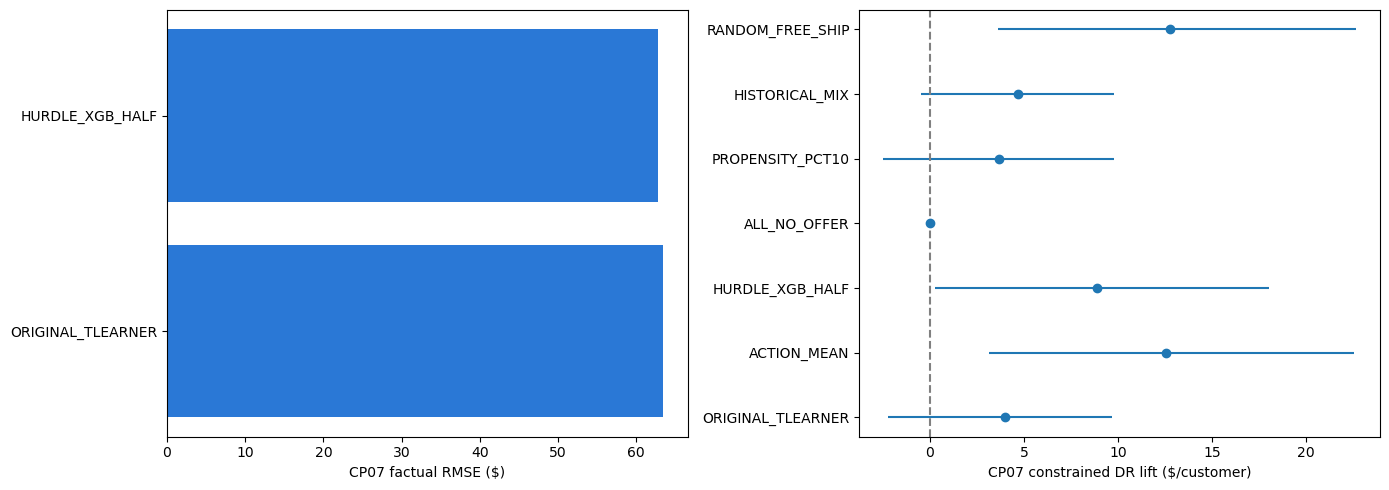

In [4]:
fig,ax=plt.subplots(1,2,figsize=(14,5))
m=model_metrics.query("scope == 'pooled'")
ax[0].barh(m.model,m.rmse,color='#2a78d6'); ax[0].set_xlabel('CP07 factual RMSE ($)')
pv=policy_metrics.set_index('policy'); x=pv.dr_incremental_ncm_per_customer.to_numpy(); y=np.arange(len(pv))
ax[1].errorbar(x,y,xerr=np.maximum(np.vstack([x-pv.ci_low.to_numpy(),pv.ci_high.to_numpy()-x]),0),fmt='o')
ax[1].set_yticks(y,pv.index); ax[1].axvline(0,color='grey',ls='--'); ax[1].set_xlabel('CP07 constrained DR lift ($/customer)')
fig.tight_layout(); fig.savefig(FIGS/'06_tlearner_diagnostics.png',dpi=120,bbox_inches='tight'); plt.show()

## Extended prediction diagnostics
Average precision and recall describe the two-part model's purchase-probability component. The recall threshold is frozen using CP04-CP06 out-of-time predictions and the same maximum-F1 rule used for logistic regression. Precision and flagged share accompany recall; a classifier can obtain 100% recall by labeling everyone a purchaser.

Signed dollar-profit prediction keeps RMSE, MAE and R2. Report mean prediction bias and predicted-versus-observed NCM bands overall and by actual offer. Separately evaluate the conditional purchaser-margin forecast only among actual purchasers. These diagnostics do not change model selection or establish profitable treatment assignment. Historical policy value above evaluates the full constrained policy on randomized outcomes; July outcomes remain unavailable.


In [5]:
from scripts.build_metric_diagnostics import build_metric_diagnostics
metric_diagnostics = build_metric_diagnostics()
for filename in ['profit_bias_by_offer.csv', 'hurdle_purchase_metrics.csv', 'purchaser_margin_metrics.csv']:
    print(filename)
    display(pd.read_csv(TABLES/filename))
print('Per-offer calibration bands: outputs/tables/profit_calibration_by_offer.csv')


    scope    n  buyers  average_precision   recall  precision  threshold
   pooled 1060     135           0.234062 0.429630   0.222222   0.151999
 NO_OFFER  257      26           0.223679 0.538462   0.212121   0.151999
   PCT_10  294      37           0.238575 0.405405   0.220588   0.151999
   PCT_20  243      36           0.279052 0.388889   0.241379   0.151999
FREE_SHIP  266      36           0.267569 0.416667   0.217391   0.151999
          model     scope   n       rmse        mae        r2   obs_mean  pred_mean  mean_prediction_bias  bias_ci_low  bias_ci_high
HURDLE_XGB_HALF    pooled 135 131.100649  85.825866  0.100048 120.249778 125.923570              5.673793   -18.835794     25.840880
HURDLE_XGB_HALF  NO_OFFER  26  91.132925  79.055472 -0.230173 101.266923 140.625254             39.358331     4.625311     68.285285
HURDLE_XGB_HALF    PCT_10  37 166.814568  91.553167  0.057510 128.609730 131.219483              2.609754   -57.261000     44.790453
HURDLE_XGB_HALF    PCT_20  36 

,model,scope,n,rmse,mae,r2,obs_mean,pred_mean,mean_prediction_bias,bias_ci_low,bias_ci_high
0,HURDLE_XGB_HALF,pooled,1060,62.738470,26.480589,0.025561,15.314830,15.975588,0.660758,-3.186698,4.396154
1,HURDLE_XGB_HALF,NO_OFFER,257,41.171565,23.701400,-0.049259,10.244903,18.217000,7.972097,2.496893,12.626420
2,HURDLE_XGB_HALF,PCT_10,294,73.937705,27.207079,0.012394,16.185578,15.672923,-0.512655,-9.874572,6.541631
3,HURDLE_XGB_HALF,PCT_20,243,35.842004,18.961864,0.089049,11.339588,11.098230,-0.241358,-4.952448,4.089362
4,HURDLE_XGB_HALF,FREE_SHIP,266,82.654232,35.231391,0.028499,22.882331,18.600169,-4.282162,-14.392994,4.429275
5,ORIGINAL_TLEARNER,pooled,1060,63.369408,27.411143,0.005863,15.314830,16.573692,1.258862,-2.624574,5.039324
6,ORIGINAL_TLEARNER,NO_OFFER,257,40.964362,23.405148,-0.038725,10.244903,17.807631,7.562728,2.075588,12.233355
7,ORIGINAL_TLEARNER,PCT_10,294,74.554528,27.128349,-0.004153,16.185578,14.794448,-1.391131,-10.961725,5.834099
8,ORIGINAL_TLEARNER,PCT_20,243,36.760015,18.540873,0.041788,11.339588,9.642219,-1.697369,-6.551416,2.753381
9,ORIGINAL_TLEARNER,FREE_SHIP,266,83.684602,39.697451,0.004127,22.882331,23.680173,0.797842,-9.468509,9.539444


hurdle_purchase_metrics.csv


,model,scope,n,buyers,average_precision,recall,precision,f1,threshold,predicted_positive_share,tp,fp,tn,fn,roc_auc,log_loss,brier
0,HURDLE_XGB_HALF,pooled,1060,135,0.234062,0.429630,0.222222,0.292929,0.151999,0.246226,58,203,722,77,0.674418,0.361255,0.106261
1,HURDLE_XGB_HALF,NO_OFFER,257,26,0.223679,0.538462,0.212121,0.304348,0.151999,0.256809,14,52,179,12,0.686147,0.310669,0.087103
2,HURDLE_XGB_HALF,PCT_10,294,37,0.238575,0.405405,0.220588,0.285714,0.151999,0.231293,15,53,204,22,0.691345,0.359425,0.105575
3,HURDLE_XGB_HALF,PCT_20,243,36,0.279052,0.388889,0.241379,0.297872,0.151999,0.238683,14,44,163,22,0.681965,0.396570,0.119644
4,HURDLE_XGB_HALF,FREE_SHIP,266,36,0.267569,0.416667,0.217391,0.285714,0.151999,0.259398,15,54,176,21,0.665821,0.379892,0.113301


purchaser_margin_metrics.csv


,model,scope,n,rmse,mae,r2,obs_mean,pred_mean,mean_prediction_bias,bias_ci_low,bias_ci_high
0,HURDLE_XGB_HALF,pooled,135,131.100649,85.825866,0.100048,120.249778,125.923570,5.673793,-18.835794,25.840880
1,HURDLE_XGB_HALF,NO_OFFER,26,91.132925,79.055472,-0.230173,101.266923,140.625254,39.358331,4.625311,68.285285
2,HURDLE_XGB_HALF,PCT_10,37,166.814568,91.553167,0.057510,128.609730,131.219483,2.609754,-57.261000,44.790453
3,HURDLE_XGB_HALF,PCT_20,36,65.024516,49.818141,0.066273,76.542222,90.889988,14.347765,-5.451848,35.844913
4,HURDLE_XGB_HALF,FREE_SHIP,36,160.081873,120.836926,0.059317,169.075000,144.896249,-24.178751,-80.263574,21.565426


Per-offer calibration bands: outputs/tables/profit_calibration_by_offer.csv
